# 01 - Análisis exploratorio de datos (EDA)

Objetivo: entender los contratos de SECOP II descargados (etapa 1) y tomar las decisiones de alcance
antes de limpiar y construir etiquetas (etapas 2 y 3). Corresponde a la fase *Data Management* de
Ashmore et al. (2021).

Requisito: haber ejecutado `python scripts/descargar_datos.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from secopedia.configuracion import cargar_config, ruta
from secopedia.etiquetas import elegir_clases, extraer_segmento
from secopedia.limpieza import limpiar_contratos
from secopedia.segmentos import nombre_segmento

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
config = cargar_config()
carpeta_figuras = ruta(config["rutas"]["figuras"] + "/x").parent

contratos = pd.read_parquet(ruta(config["rutas"]["crudos"]))
contratos["segmento"] = contratos["codigo_de_categoria_principal"].str.extract(r"^V1\.(\d{2})", expand=False)
contratos["anio"] = contratos["fecha_de_firma"].dt.year
print(f"Contratos descargados: {len(contratos):,}")
print(f"Columnas: {list(contratos.columns)}")
contratos.head()

Contratos descargados: 585,990
Columnas: ['id_contrato', 'objeto_del_contrato', 'descripcion_del_proceso', 'codigo_de_categoria_principal', 'tipo_de_contrato', 'fecha_de_firma', 'segmento', 'anio']


,id_contrato,objeto_del_contrato,descripcion_del_proceso,codigo_de_categoria_principal,tipo_de_contrato,fecha_de_firma,segmento,anio
0,CO1.PCCNTR.3279574,Delegación de funciones del Ministerio de Cultura al Distrito Especial; Industrial y Portuario de Barranquilla; para...,Delegación de funciones del Ministerio de Cultura al Distrito Especial; Industrial y Portuario de Barranquilla; para...,V1.93141700,Otro,2022-01-19 21:13:45.868,93,2022
1,CO1.PCCNTR.6239103,SUSCRIBIR UN CONTRATO DE FIDUCIA MERCANTIL PARA LA ADMINISTRACIÓN DE LOS RECURSOS DEL FONDO NACIONAL DE SALUD DE LAS...,SUSCRIBIR UN CONTRATO DE FIDUCIA MERCANTIL PARA LA ADMINISTRACIÓN DE LOS RECURSOS DEL FONDO NACIONAL DE SALUD DE LAS...,V1.93151500,Negocio fiduciario,2024-04-26 16:01:46.595,93,2024
2,CO1.PCCNTR.4515200,PRESTAR EL SERVICIO DE EDUCACIÓN INICIAL EN EL MARCO DE LA ATENCIÓN INTEGRAL EN HOGARES INFANTILES -HI-; DE CONFORMI...,PRESTAR EL SERVICIO DE EDUCACIÓN INICIAL EN EL MARCO DE LA ATENCIÓN INTEGRAL EN HOGARES INFANTILES -HI-; DE CONFORMI...,V1.93141500,Otro,2023-01-30 17:04:55.411,93,2023
3,CO1.PCCNTR.9375986,REEMPLAZO DEL PUENTE DOS RIOS EN EL\nDEPARTAMENTO DEL CAUCA EN EL MARCO DEL\nPROGRAMA VÍAS PARA LA PAZ.,REEMPLAZO DEL PUENTE DOS RIOS EN EL\nDEPARTAMENTO DEL CAUCA EN EL MARCO DEL\nPROGRAMA VÍAS PARA LA PAZ.,V1.72141000,Obra,2026-05-28 12:06:43.975,72,2026
4,CO1.PCCNTR.7570086,SUMINISTRO DE MATERIAL MEDICO QUIRURGICO E INSUMO FARMACEUTICO PARA EL AREA DE URGENCIAS DEL CENTRO DE SALUD FUNES,SUMINISTRO DE MATERIAL MEDICO QUIRURGICO E INSUMO FARMACEUTICO PARA EL AREA DE URGENCIAS DEL CENTRO DE SALUD FUNES,V1.42292900,Suministros,2025-02-27 09:58:32.165,42,2025


## 1. Contratos por tipo

                                contratos   pct
tipo_de_contrato                               
Decreto 092 de 2017                166270  28.4
Otro                               145750  24.9
Suministros                         96490  16.5
Compraventa                         68512  11.7
Obra                                37444   6.4
Arrendamiento de inmuebles          32725   5.6
Interventoría                        9012   1.5
Comodato                             8501   1.5
Seguros                              8289   1.4
Consultoría                          7991   1.4
Arrendamiento de muebles             1666   0.3
Servicios financieros                 937   0.2
Acuerdo Marco de Precios              670   0.1
Operaciones de Crédito Público        544   0.1
Venta muebles                         380   0.1
Asociación Público Privada            163   0.0
Negocio fiduciario                    153   0.0
No Especificado                       125   0.0
Concesión                             12

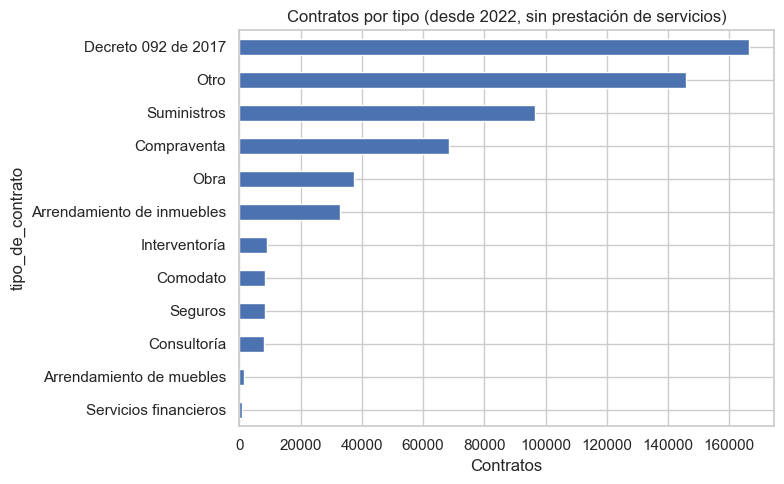

In [2]:
por_tipo = contratos["tipo_de_contrato"].value_counts()
tabla_tipos = pd.DataFrame({"contratos": por_tipo, "pct": (100 * por_tipo / len(contratos)).round(1)})
print(tabla_tipos.to_string())

fig, eje = plt.subplots(figsize=(8, 5))
por_tipo.head(12).sort_values().plot.barh(ax=eje, color="#4C72B0")
eje.set_xlabel("Contratos")
eje.set_title("Contratos por tipo (desde 2022, sin prestación de servicios)")
plt.tight_layout()
fig.savefig(carpeta_figuras / "contratos_por_tipo.png", dpi=150)

## 2. ¿La etiqueta es informativa en cada tipo de contrato?

En *Prestación de servicios* casi todo queda en códigos `801116xx` (personal temporal), por eso se excluyó. Aquí se revisa si
pasa lo mismo con "Otro" y "Decreto 092 de 2017". Se mide, por tipo: el porcentaje del código más
frecuente, el porcentaje de códigos `801116xx` y cuántos segmentos distintos aparecen.

In [3]:
def resumen_etiqueta(grupo):
    codigos = grupo["codigo_de_categoria_principal"]
    return pd.Series({
        "contratos": len(grupo),
        "codigo_mas_frecuente": codigos.mode().iat[0],
        "pct_codigo_mas_frecuente": round(100 * codigos.value_counts(normalize=True).iat[0], 1),
        "pct_801116xx": round(100 * codigos.str.startswith("V1.801116").mean(), 1),
        "segmentos_distintos": grupo["segmento"].nunique(),
        "pct_segmento_80": round(100 * (grupo["segmento"] == "80").mean(), 1),
    })

tipos_principales = por_tipo.head(10).index
resumen_tipos = (
    contratos[contratos["tipo_de_contrato"].isin(tipos_principales)]
    .groupby("tipo_de_contrato")
    .apply(resumen_etiqueta, include_groups=False)
    .sort_values("contratos", ascending=False)
)
resumen_tipos

,contratos,codigo_mas_frecuente,pct_codigo_mas_frecuente,pct_801116xx,segmentos_distintos,pct_segmento_80
tipo_de_contrato,,,,,,
Decreto 092 de 2017,166270,V1.80111600,20.3,25.2,56,35.9
Otro,145750,V1.93141500,15.7,4.7,56,17.3
Suministros,96490,UNSPECIFIED,2.7,1.2,56,2.9
Compraventa,68512,UNSPECIFIED,2.5,0.5,56,1.4
Obra,37444,UNSPECIFIED,15.4,0.7,55,3.0
Arrendamiento de inmuebles,32725,V1.80131500,56.2,0.7,36,95.1
Interventoría,9012,V1.81101500,39.5,2.3,35,36.2
Comodato,8501,V1.80131500,12.9,0.9,50,35.7
Seguros,8289,V1.84131500,37.4,1.0,32,2.2


In [4]:
for tipo in ["Otro", "Decreto 092 de 2017"]:
    muestra = contratos[contratos["tipo_de_contrato"] == tipo].sample(8, random_state=42)
    print(f"--- {tipo}")
    for _, fila in muestra.iterrows():
        print(f"  [{fila['segmento']}] {fila['objeto_del_contrato'][:110]}")

--- Otro
  [80] Aunar esfuerzos técnicos; administrativos y financieros para desarrollar el proyecto: CUALIFICACION TRANSVERSA
  [nan] PRESTACIÓN DE SERVICIOS DE SALUD PARA LAS PATOLOGÍAS OSTEOMUSCULARES Y DEL DESEMPEÑO FUNCIONAL Y REHABILITACIÓ
  [93] BRINDAR ATENCIÓN A LAS NIÑAS Y ADOLESCENTES QUE TIENEN UN PROCESO ADMINISTRATIVO DE RESTABLECIMIENTO DE DERECH
  [80] REALIZAR LOS AJUSTES A LOS DISEÑOS DE REDES SECAS DEL PARQUE FERNANDO GONZÁLEZ EN EL MUNICIPIO DE ENVIGADO; EN
  [93] Complementar la atención de niños y niñas a través de la entrega de alimentos para fortalecer el componente al
  [81] ESTUDIOS Y DISEÑOS PARA LA OPTIMIZACIÓN DEL ALCANTARILLADO SANITARIO; INCLUYE ACTUALIZACIÓN DEL CATASTRO DE RE
  [95] ADQUISICIÓN A TÍTULO DE COMPRAVENTA DEL BIEN INMUEBLE CON MATRÍCULA INMOBILIARIA NO. 024-14630; UBICADO EN LA 
  [72] AUNAR ESFUERZOS ENTRE EL MUNICIPIO DE SAN JERÓNIMO ANTIOQUIA Y LA JUNTA DE ACCIÓN COMUNAL VEREDA EL POMAR; PAR
--- Decreto 092 de 2017
  [92] AUNAR ESFUERZOS

## 3. Distribución de segmentos UNSPSC (datos crudos)

Las clases del modelo no se eligen aquí, sino después de limpiar (sección 7).

In [5]:
por_segmento = contratos["segmento"].value_counts()
tabla_segmentos = pd.DataFrame({
    "nombre": [nombre_segmento(s) for s in por_segmento.index],
    "contratos": por_segmento,
    "pct": (100 * por_segmento / por_segmento.sum()).round(1),
})
print(f"Segmentos distintos: {len(por_segmento)}")
print(f"Los 4 segmentos más frecuentes suman el {tabla_segmentos['pct'].head(4).sum():.1f}% de los contratos")
tabla_segmentos.head(30)

Segmentos distintos: 56
Los 4 segmentos más frecuentes suman el 52.9% de los contratos


,nombre,contratos,pct
segmento,,,
80,"Servicios de gestión, profesionales de empresa y administrativos",131808,23.1
93,Servicios políticos y de asuntos cívicos,63315,11.1
85,Servicios de salud,63239,11.1
72,"Servicios de edificación, construcción y mantenimiento",43589,7.6
81,"Servicios de ingeniería, investigación y tecnología",26272,4.6
43,Tecnologías de la información y telecomunicaciones,14666,2.6
42,"Equipo médico, accesorios y suministros",14302,2.5
84,Servicios financieros y de seguros,13219,2.3
90,"Servicios de viajes, alimentación, alojamiento y entretenimiento",12812,2.2


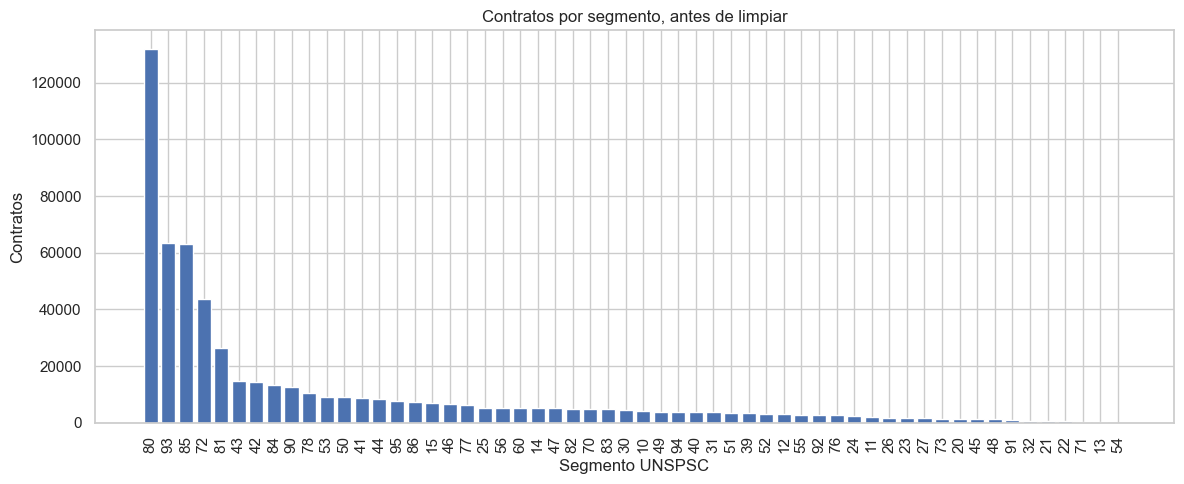

In [6]:
fig, eje = plt.subplots(figsize=(12, 5))
eje.bar(por_segmento.index, por_segmento.values, color="#4C72B0")
eje.set_xlabel("Segmento UNSPSC")
eje.set_ylabel("Contratos")
eje.set_title("Contratos por segmento, antes de limpiar")
plt.xticks(rotation=90)
plt.tight_layout()
fig.savefig(carpeta_figuras / "distribucion_segmentos.png", dpi=150)

## 4. Longitud de los textos

count    585990.0
mean         35.1
std          17.4
min           1.0
5%           13.0
50%          31.0
95%          70.0
99%          80.0
max         132.0


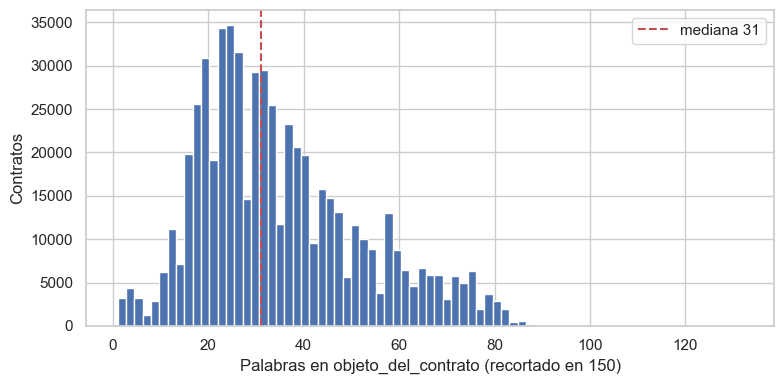

In [7]:
palabras = contratos["objeto_del_contrato"].fillna("").str.split().str.len()
print(palabras.describe(percentiles=[0.05, 0.5, 0.95, 0.99]).round(1).to_string())

fig, eje = plt.subplots(figsize=(8, 4))
eje.hist(palabras.clip(upper=150), bins=75, color="#4C72B0")
eje.axvline(palabras.median(), color="#C44E52", linestyle="--", label=f"mediana {palabras.median():.0f}")
eje.set_xlabel("Palabras en objeto_del_contrato (recortado en 150)")
eje.set_ylabel("Contratos")
eje.legend()
plt.tight_layout()
fig.savefig(carpeta_figuras / "longitud_textos.png", dpi=150)

## 5. Contratos por año (para la prueba temporal)

In [8]:
por_anio = contratos["anio"].value_counts().sort_index()
print(por_anio.to_string())
print(f"Fecha más reciente: {contratos['fecha_de_firma'].max()}")

anio
2022     92514
2023    112904
2024    124553
2025    147491
2026    108528
Fecha más reciente: 2026-11-15 12:06:49.292000


## 6. Calidad: códigos inválidos, duplicados y ruido de etiquetas

Se aplica la etapa 2 (`limpiar_contratos`) para cuantificar lo que se elimina en cada paso.

In [9]:
limpios, conflictos, reporte = limpiar_contratos(contratos, config["limpieza"])
reporte.como_tabla()

,paso,antes,despues,eliminados,pct_eliminado
0,texto vacío o con menos de 3 palabras,585990,582879,3111,0.53
1,código UNSPSC inválido,582879,568458,14421,2.47
2,código por defecto (V1.801116),568458,517191,51267,9.02
3,fecha de firma inválida,517191,517191,0,0.00
4,duplicados de texto y código,517191,395736,121455,23.48
5,mismo texto con varios códigos (se deja uno),395736,373954,21782,5.50


In [10]:
print(f"Textos idénticos con segmentos distintos: {conflictos['clave_texto'].nunique():,}")
ejemplos = (
    conflictos.groupby("clave_texto")["segmento"]
    .agg(lambda s: sorted(set(s)))
    .reset_index()
    .assign(n=lambda d: d["segmento"].str.len())
    .sort_values("n", ascending=False)
    .head(10)
)
ejemplos

Textos idénticos con segmentos distintos: 8,771


,clave_texto,segmento,n
4131,entregar a titulo de comodato los bienes muebles para el fortalecimiento de los emprendimientos y unidades productiv...,"[11, 20, 21, 23, 24, 26, 27, 31, 40, 41, 45, 47, 48, 52, 56]",15
2106,complementar la atencion de ninos y ninas a traves de la entrega de alimentos para fortalecer el componente alimenta...,"[24, 41, 49, 70, 78, 80, 85, 93, 94]",9
8193,suministro de productos para el almacen,"[13, 14, 24, 42, 44, 47, 50, 55]",8
1742,aunar esfuerzos recursos y experiencia para brindar atencion a adultos mayores en estado de vulnerabilidad en centro...,"[14, 47, 53, 80, 93, 94]",6
3606,contrato de suministro,"[14, 41, 42, 51, 52, 85]",6
4295,gerencia integral de proyectos para participar en el festival expocundinamarca 2025 kuntur fest de acuerdo a las act...,"[56, 80, 81, 86, 90, 93]",6
7749,suministro de materiales e insumos de ferreteria y mantenimiento para el hospital san rafael e s e,"[14, 53, 72, 81, 85, 93]",6
3953,el comodatario recibe del comodante en prestamo de uso a titulo gratuito y con cargo a restituir bienes muebles de p...,"[32, 43, 44, 49, 52, 56]",6
7276,suministro de insumos a monto agotable para la prestacion de servicios de laboratorio y odontologia en la e s e hosp...,"[41, 42, 44, 47, 51]",5
4367,integrar esfuerzos para la ejecucion del programa de alimentacion escolar pae para los ninos ninas y adolescentes de...,"[10, 48, 50, 85, 93]",5


## 7. Clases finales

Las clases se eligen con los contratos **limpios y anteriores a 2026**, para no usar información de la prueba
temporal. Los segmentos que no llegan al umbral se agrupan en "otros".

In [11]:
corte = pd.Timestamp(config["etiquetas"]["fecha_corte_temporal"])
historicos = limpios[limpios["fecha_de_firma"] < corte]
segmentos_limpios = historicos["codigo_de_categoria_principal"].map(extraer_segmento)
minimo = config["etiquetas"]["min_ejemplos_por_segmento"]
clases = elegir_clases(segmentos_limpios, minimo)
conteo = segmentos_limpios.value_counts()
print(f"Contratos limpios: {len(limpios):,} | anteriores a 2026: {len(historicos):,} | de 2026: {len(limpios) - len(historicos):,}")
for umbral in [2000, 3000, 4000, 5000]:
    elegidas = elegir_clases(segmentos_limpios, umbral)
    print(f"Umbral {umbral:,}: {len(elegidas)} segmentos, cubren el {segmentos_limpios.isin(elegidas).mean():.1%} de los contratos")
print(f"Clases con el umbral elegido ({minimo:,}): {clases}")
print(f"Desbalance entre la clase más grande y la más pequeña: {conteo[clases].max() / conteo[clases].min():.1f}x")

Contratos limpios: 373,954 | anteriores a 2026: 310,454 | de 2026: 63,500
Umbral 2,000: 36 segmentos, cubren el 93.5% de los contratos
Umbral 3,000: 28 segmentos, cubren el 86.8% de los contratos
Umbral 4,000: 20 segmentos, cubren el 77.8% de los contratos
Umbral 5,000: 17 segmentos, cubren el 73.5% de los contratos
Clases con el umbral elegido (3,000): ['14', '15', '25', '30', '41', '42', '43', '44', '46', '47', '50', '53', '56', '60', '70', '72', '77', '78', '80', '81', '82', '83', '84', '85', '86', '90', '93', '95']
Desbalance entre la clase más grande y la más pequeña: 15.9x


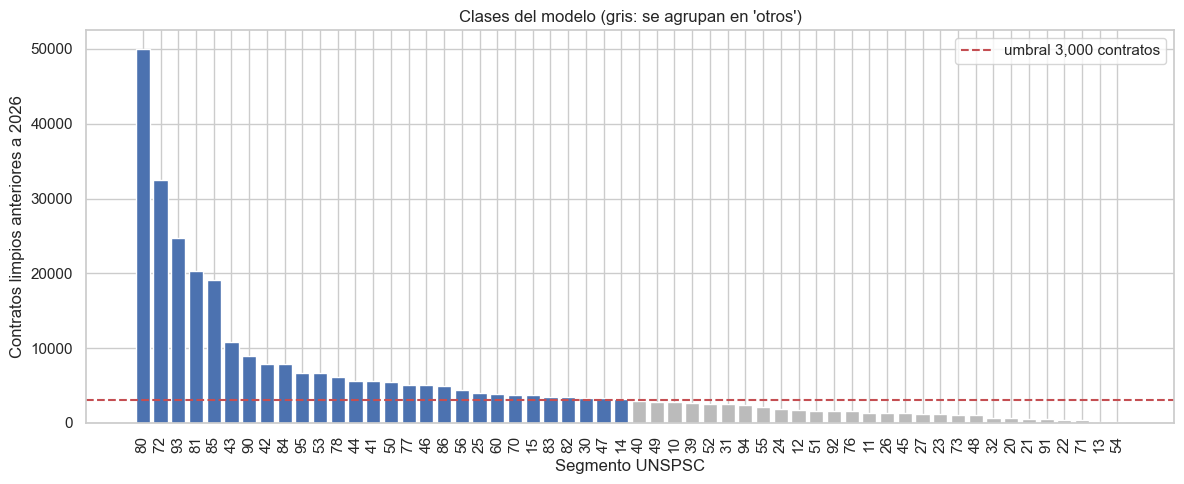

In [12]:
fig, eje = plt.subplots(figsize=(12, 5))
eje.bar(conteo.index, conteo.values, color=["#4C72B0" if s in clases else "#BBBBBB" for s in conteo.index])
eje.axhline(minimo, color="#C44E52", linestyle="--", label=f"umbral {minimo:,} contratos")
eje.set_xlabel("Segmento UNSPSC")
eje.set_ylabel("Contratos limpios anteriores a 2026")
eje.set_title("Clases del modelo (gris: se agrupan en 'otros')")
eje.legend()
plt.xticks(rotation=90)
plt.tight_layout()
fig.savefig(carpeta_figuras / "clases_finales.png", dpi=150)

## 8. Conclusiones

1. **Tipos de contrato.** Hay 585.990 contratos desde 2022, sin prestación de servicios. "Decreto 092 de 2017" (28,4%) y "Otro" (24,9%) son más de la mitad. Se conservan porque cubren los 56 segmentos: solo el 25,2% y el 4,7% usan códigos `801116xx`. Esos códigos (personal temporal) se excluyen en **todos** los tipos, porque no describen lo que se contrata.
2. **Calidad.** La limpieza deja **373.954 contratos (63,8%)**. Lo que más se elimina son los duplicados de texto y código (121.455), seguido del código por defecto 801116 (51.267), los textos repetidos con varios códigos (21.782) y los códigos inválidos (14.421).
3. **Ruido en las etiquetas.** **8.771 textos idénticos aparecen con segmentos distintos**; uno de ellos, en 15 segmentos. Con solo el texto, ningún modelo puede acertar siempre en esos casos.
4. **Clases.** Con un umbral de 3.000 contratos limpios anteriores a 2026 quedan **28 segmentos, que cubren el 86,8%**, y el resto va a la clase "otros". Con 4.000 quedarían 20 segmentos y 77,8%; con 2.000, 36 segmentos y 93,5%, pero con clases más pequeñas.
5. **Desbalance.** La clase más grande tiene 15,9 veces los contratos de la más pequeña, sin contar "otros". Por eso se aplica un tope de 5.000 contratos por clase y la métrica principal es F1 macro.
6. **Longitud.** La mediana es de 31 palabras, y el 99% de los textos tiene 80 o menos. Son textos cortos, por lo que 128 subpalabras para BETO alcanzan en la mayoría de los casos.
7. **Prueba temporal.** Hay contratos de 2026 hasta el 15 de noviembre. Quedan **63.500 limpios de 2026**, de los que se toman 20.000 como prueba temporal, con su distribución real.